# تشخیص عنوان فارسی کتاب با مدل چندوجهی

این نوت‌بوک یک اجرای کامل و قابل‌بازتولید از آماده‌سازی داده، ارزیابی مدل پایه، فاین‌تیون QLoRA و مقایسه نهایی روی ۲۰۰ نمونه آزمون است.

پیش از اجرا، در تنظیمات Kaggle گزینه‌های **GPU** و **Internet** را فعال کنید. برای تحویل نهایی از **Save Version → Save & Run All** استفاده کنید.


## ۱. نصب نسخه‌های ثابت کتابخانه‌ها


In [1]:
%pip install -q --upgrade \
    "transformers==4.57.1" \
    "huggingface_hub==0.36.0" \
    "bitsandbytes==0.50.2" \
    "accelerate==1.13.0" \
    "peft==0.19.1" \
    "qwen-vl-utils==0.0.14"


Note: you may need to restart the kernel to use updated packages.


## ۲. واردکردن کتابخانه‌ها و بررسی محیط


In [2]:
import copy
import gc
import io
import json
import math
import re
import shutil
import sys
import unicodedata
from collections import Counter
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import PIL
import torch
from datasets import Dataset, Image as HFImage, load_dataset, load_from_disk
from IPython.display import display
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from PIL import Image as PILImage
from qwen_vl_utils import process_vision_info
from tqdm.auto import tqdm
from transformers import (
    AutoProcessor,
    BitsAndBytesConfig,
    Qwen2_5_VLForConditionalGeneration,
    Trainer,
    TrainingArguments,
    set_seed,
)
from transformers.trainer_utils import get_last_checkpoint

set_seed(42)

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("transformers:", version("transformers"))
print("huggingface_hub:", version("huggingface_hub"))
print("bitsandbytes:", version("bitsandbytes"))
print("accelerate:", version("accelerate"))
print("peft:", version("peft"))
print("qwen-vl-utils:", version("qwen-vl-utils"))
print("datasets:", version("datasets"))
print("Pillow:", PIL.__version__)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "GPU در دسترس نیست"

print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory:",
    round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
    "GB",
)


Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
PyTorch: 2.10.0+cu128
transformers: 4.57.1
huggingface_hub: 0.36.0
bitsandbytes: 0.50.2
accelerate: 1.13.0
peft: 0.19.1
qwen-vl-utils: 0.0.14
datasets: 5.0.0
Pillow: 11.3.0
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


## ۳. آماده‌سازی داده‌های آموزش و آزمون


In [3]:
DATASET_ID = "shenasa/bookroom-persian-book-covers-and-titles"
MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

WORK_DIR = Path("/kaggle/working")
MANIFEST_PATH = WORK_DIR / "selection_manifest.json"
TRAIN_CACHE_PATH = WORK_DIR / "book_train_1000"
TEST_CACHE_PATH = WORK_DIR / "book_test_200"


def load_raw_split(split_name):
    stream = load_dataset(
        DATASET_ID,
        split=split_name,
        streaming=True,
    )
    return stream.cast_column("image", HFImage(decode=False))


def read_and_validate_image(image_data):
    raw_bytes = image_data.get("bytes")
    if raw_bytes is None:
        raw_bytes = Path(image_data["path"]).read_bytes()

    with PILImage.open(io.BytesIO(raw_bytes)) as image:
        image.load()
        if image.width == 0 or image.height == 0:
            raise ValueError("Invalid image dimensions")

    return {"bytes": raw_bytes, "path": None}


def collect_healthy_samples(split_name, required_count):
    healthy = []
    errors = []

    for source_index, sample in enumerate(load_raw_split(split_name)):
        try:
            title = str(sample["text"]).strip()
            if not title:
                raise ValueError("Empty title")

            healthy.append({
                "image": read_and_validate_image(sample["image"]),
                "text": title,
                "source_index": source_index,
            })

            if len(healthy) % 100 == 0:
                print(f"{split_name}: {len(healthy)}/{required_count}")

        except Exception as error:
            errors.append({
                "source_index": source_index,
                "error_type": type(error).__name__,
                "message": str(error)[:200],
            })

        if len(healthy) == required_count:
            break

    if len(healthy) < required_count:
        raise RuntimeError(
            f"Only {len(healthy)} healthy samples found in {split_name}"
        )

    dataset = Dataset.from_list(healthy).cast_column("image", HFImage())
    return dataset, errors


In [4]:
cache_is_complete = (
    MANIFEST_PATH.exists()
    and TRAIN_CACHE_PATH.exists()
    and TEST_CACHE_PATH.exists()
)

if cache_is_complete:
    train_1000 = load_from_disk(str(TRAIN_CACHE_PATH))
    test_200 = load_from_disk(str(TEST_CACHE_PATH))
    selection_manifest = json.loads(
        MANIFEST_PATH.read_text(encoding="utf-8")
    )
    train_errors = selection_manifest["train_errors"]
    test_errors = selection_manifest["test_errors"]
    print("Datasets loaded from disk cache.")
else:
    train_1000, train_errors = collect_healthy_samples("train", 1000)
    test_200, test_errors = collect_healthy_samples("test", 200)

    selection_manifest = {
        "train_indices": [int(x) for x in train_1000["source_index"]],
        "test_indices": [int(x) for x in test_200["source_index"]],
        "train_errors": train_errors,
        "test_errors": test_errors,
    }

    MANIFEST_PATH.write_text(
        json.dumps(selection_manifest, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    train_1000.save_to_disk(str(TRAIN_CACHE_PATH))
    test_200.save_to_disk(str(TEST_CACHE_PATH))
    print("Datasets and manifest saved.")

assert len(train_1000) == 1000
assert len(test_200) == 200
assert [int(x) for x in train_1000["source_index"]] == selection_manifest["train_indices"]
assert [int(x) for x in test_200["source_index"]] == selection_manifest["test_indices"]

print("Train samples:", len(train_1000))
print("Test samples:", len(test_200))
print("Train errors:", len(train_errors))
print("Test errors:", len(test_errors))
print("Train columns:", train_1000.column_names)
print("Test columns:", test_200.column_names)


README.md:   0%|          | 0.00/417 [00:00<?, ?B/s]

train: 100/1000
train: 200/1000
train: 300/1000
train: 400/1000
train: 500/1000
train: 600/1000
train: 700/1000
train: 800/1000
train: 900/1000
train: 1000/1000
test: 100/200
test: 200/200


Saving the dataset (0/1 shards):   0%|          | 0/1000 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/200 [00:00<?, ? examples/s]

Datasets and manifest saved.
Train samples: 1000
Test samples: 200
Train errors: 0
Test errors: 0
Train columns: ['image', 'text', 'source_index']
Test columns: ['image', 'text', 'source_index']


Sample: 0
Reference: روزنه ای به چشمه های نور


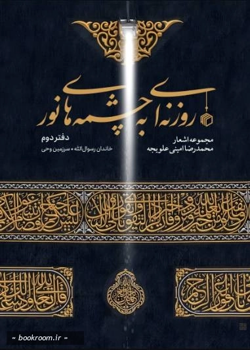

Sample: 1
Reference: ساواک و مرجعیت (1357 - 1335)


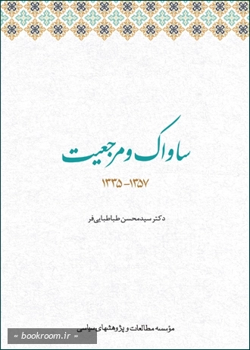

Sample: 2
Reference: پسر خدا


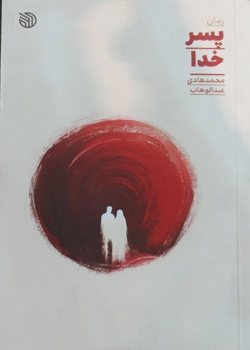

Sample: 3
Reference: نمک در چشمانم می ریزم


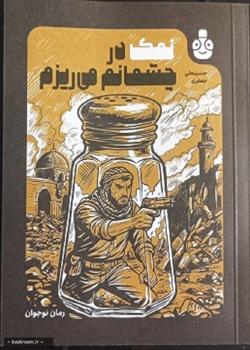

Sample: 4
Reference: رد شدن از خیابان فیل ها


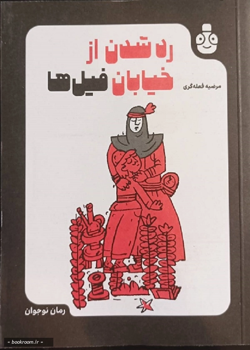

In [5]:
for sample_index in range(5):
    sample = train_1000[sample_index]
    print("Sample:", sample_index)
    print("Reference:", sample["text"])
    display(sample["image"].convert("RGB").resize((250, 350)))


## ۴. تعریف معیارهای ارزیابی


In [6]:
def normalize_persian(text):
    text = unicodedata.normalize("NFC", str(text).strip())
    text = text.translate(str.maketrans({
        "ي": "ی",
        "ى": "ی",
        "ك": "ک",
        "ة": "ه",
        "ۀ": "ه",
    }))
    text = re.sub(r"[\u064B-\u065F\u0670]", "", text)
    text = text.replace("\u200c", " ")
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def levenshtein_distance(first_text, second_text):
    if len(first_text) < len(second_text):
        return levenshtein_distance(second_text, first_text)
    if len(second_text) == 0:
        return len(first_text)

    previous_row = list(range(len(second_text) + 1))

    for row_index, first_character in enumerate(first_text, start=1):
        current_row = [row_index]
        for column_index, second_character in enumerate(second_text, start=1):
            insertion_cost = current_row[column_index - 1] + 1
            deletion_cost = previous_row[column_index] + 1
            substitution_cost = (
                previous_row[column_index - 1]
                + (first_character != second_character)
            )
            current_row.append(min(
                insertion_cost,
                deletion_cost,
                substitution_cost,
            ))
        previous_row = current_row

    return previous_row[-1]


def calculate_text_metrics(reference, prediction):
    reference_raw = str(reference).strip()
    prediction_raw = str(prediction).strip()
    reference_normalized = normalize_persian(reference_raw)
    prediction_normalized = normalize_persian(prediction_raw)

    maximum_length = max(
        len(reference_normalized),
        len(prediction_normalized),
    )
    if maximum_length == 0:
        levenshtein_similarity = 1.0
    else:
        edit_distance = levenshtein_distance(
            reference_normalized,
            prediction_normalized,
        )
        levenshtein_similarity = 1.0 - edit_distance / maximum_length

    reference_words = reference_normalized.split()
    prediction_words = prediction_normalized.split()

    if not reference_words and not prediction_words:
        word_f1 = 1.0
    elif not reference_words or not prediction_words:
        word_f1 = 0.0
    else:
        reference_counter = Counter(reference_words)
        prediction_counter = Counter(prediction_words)
        common_word_count = sum(
            (reference_counter & prediction_counter).values()
        )
        precision = common_word_count / len(prediction_words)
        recall = common_word_count / len(reference_words)
        word_f1 = (
            0.0
            if precision + recall == 0
            else 2 * precision * recall / (precision + recall)
        )

    return {
        "raw_exact_match": int(reference_raw == prediction_raw),
        "normalized_exact_match": int(
            reference_normalized == prediction_normalized
        ),
        "levenshtein_similarity": levenshtein_similarity,
        "word_f1": word_f1,
    }


METRIC_COLUMNS = [
    "raw_exact_match",
    "normalized_exact_match",
    "levenshtein_similarity",
    "word_f1",
]

print("Metric functions are ready.")


Metric functions are ready.


## ۵. بارگذاری مدل پایه و تعریف Prompt نهایی


In [7]:
PROMPT_V2 = (
    "متن روی جلد را بررسی کن و فقط عنوان کامل کتاب را بنویس. "
    "عنوان کامل شامل عنوان اصلی و زیرعنوان مرتبط است؛ حتی اگر "
    "در چند خط، اندازه متفاوت یا کادرهای جدا نوشته شده باشند، "
    "آن‌ها را به ترتیب از بالا به پایین ترکیب کن. "
    "نام نویسنده، مترجم، گردآورنده، ناشر، نوبت چاپ و عبارت‌هایی "
    "مانند چاپ اول یا چاپ دوم را حذف کن. "
    "متن را دقیقاً به همان زبان و املای روی جلد بنویس؛ "
    "ترجمه، اصلاح، تکمیل و حدس‌زدن ممنوع است. "
    "فقط یک خط و بدون توضیح یا گیومه پاسخ بده."
)

TRAINING_PROMPT = PROMPT_V2
EVALUATION_PROMPT = PROMPT_V2

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)

gc.collect()
torch.cuda.empty_cache()

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    device_map="auto",
    dtype=torch.float16,
    low_cpu_mem_usage=True,
)

processor = AutoProcessor.from_pretrained(
    MODEL_ID,
    min_pixels=256 * 28 * 28,
    max_pixels=768 * 28 * 28,
)

generation_config = copy.deepcopy(model.generation_config)
generation_config.do_sample = False
generation_config.temperature = None
generation_config.top_p = None
generation_config.top_k = None
generation_config.max_new_tokens = 64

model.eval()

print("Model loaded successfully.")
print("Model device:", next(model.parameters()).device)
print("Prompt:", EVALUATION_PROMPT)


config.json: 0.00B [00:00, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/3.98G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/3.53G [00:00<?, ?B/s]

...

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

Model loaded successfully.
Model device: cuda:0
Prompt: متن روی جلد را بررسی کن و فقط عنوان کامل کتاب را بنویس. عنوان کامل شامل عنوان اصلی و زیرعنوان مرتبط است؛ حتی اگر در چند خط، اندازه متفاوت یا کادرهای جدا نوشته شده باشند، آن‌ها را به ترتیب از بالا به پایین ترکیب کن. نام نویسنده، مترجم، گردآورنده، ناشر، نوبت چاپ و عبارت‌هایی مانند چاپ اول یا چاپ دوم را حذف کن. متن را دقیقاً به همان زبان و املای روی جلد بنویس؛ ترجمه، اصلاح، تکمیل و حدس‌زدن ممنوع است. فقط یک خط و بدون توضیح یا گیومه پاسخ بده.


In [8]:
def generate_title(image):
    image = image.convert("RGB")
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": EVALUATION_PROMPT},
        ],
    }]

    chat_text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    image_inputs, video_inputs = process_vision_info(messages)
    model_inputs = processor(
        text=[chat_text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    ).to(model.device)

    with torch.inference_mode():
        generated_ids = model.generate(
            **model_inputs,
            generation_config=generation_config,
        )

    input_length = model_inputs["input_ids"].shape[1]
    generated_text_ids = generated_ids[:, input_length:]
    prediction = processor.batch_decode(
        generated_text_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0].strip()

    del model_inputs, generated_ids, generated_text_ids
    return prediction


print("Inference function is ready.")


Inference function is ready.


## ۶. ارزیابی مدل پایه روی ۲۰۰ نمونه آزمون


In [9]:
BASELINE_PATH = WORK_DIR / "baseline_v2_results.csv"

if BASELINE_PATH.exists():
    baseline_results = pd.read_csv(BASELINE_PATH).to_dict("records")
else:
    baseline_results = []

start_index = len(baseline_results)

for sample_index in tqdm(
    range(start_index, len(test_200)),
    initial=start_index,
    total=len(test_200),
    desc="Baseline evaluation",
):
    sample = test_200[sample_index]
    reference_title = str(sample["text"]).strip()
    prediction = generate_title(sample["image"])
    sample_metrics = calculate_text_metrics(reference_title, prediction)

    baseline_results.append({
        "sample_index": sample_index,
        "source_index": int(sample["source_index"]),
        "reference": reference_title,
        "prediction": prediction,
        **sample_metrics,
    })

    if (sample_index + 1) % 10 == 0 or sample_index + 1 == len(test_200):
        pd.DataFrame(baseline_results).to_csv(
            BASELINE_PATH,
            index=False,
            encoding="utf-8-sig",
        )

baseline_df = pd.DataFrame(baseline_results)
assert len(baseline_df) == 200
baseline_summary = baseline_df[METRIC_COLUMNS].mean()

display(baseline_df.head(5))
display(baseline_summary.to_frame(name="baseline"))
print("Baseline results saved:", BASELINE_PATH)


Baseline evaluation:   0%|          | 0/200 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


,sample_index,source_index,reference,prediction,raw_exact_match,normalized_exact_match,levenshtein_similarity,word_f1
0,0,0,تاریخ جنگ های صلیبی (دوره سه جلدی),تاریخ جنگ‌های صلیبی: جلد اول,0,0,0.617647,0.461538
1,1,1,خلوت مدیر,خط مرد علي اکبر والی,0,0,0.200000,0.000000
2,2,2,فرهنگ جامع فرق اسلامی (دوره سه جلدی),"""فناکت عابد و قتله""",0,0,0.222222,0.000000
3,3,3,سمت خدا (دریافت هایی از اساتید اخلاق): به سوی نور,نوران,0,0,0.061224,0.000000
4,4,4,شهادت نامه امام حسین (ع) بر پایه منابع معتبر,شادت نمره اما حسین برپایی می‌مند نقیض جبل و دو...,0,0,0.372881,0.090909


,baseline
raw_exact_match,0.045000
normalized_exact_match,0.050000
levenshtein_similarity,0.479972
word_f1,0.340218


Baseline results saved: /kaggle/working/baseline_v2_results.csv


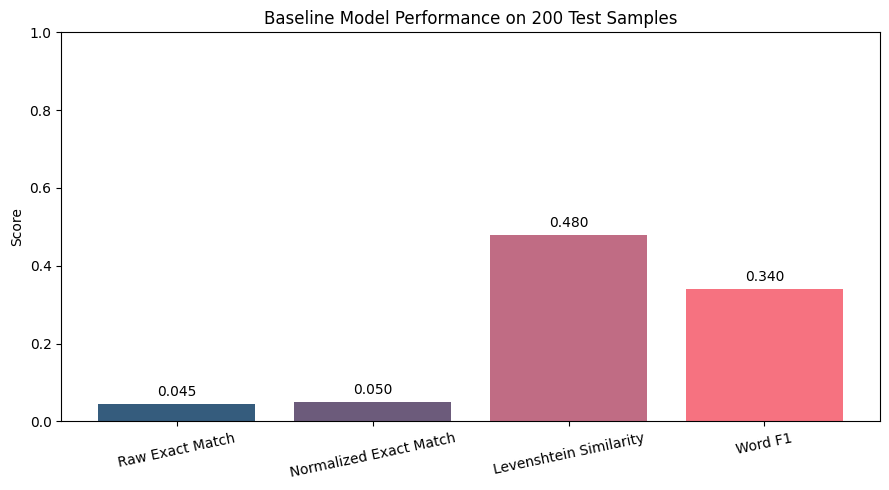

Figure saved: /kaggle/working/figure_1_baseline_metrics.png


In [10]:
FIGURE_1_PATH = WORK_DIR / "figure_1_baseline_metrics.png"

metric_labels = [
    "Raw Exact Match",
    "Normalized Exact Match",
    "Levenshtein Similarity",
    "Word F1",
]
metric_values = baseline_summary[METRIC_COLUMNS].tolist()

plt.figure(figsize=(9, 5))
bars = plt.bar(
    metric_labels,
    metric_values,
    color=["#355C7D", "#6C5B7B", "#C06C84", "#F67280"],
)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Baseline Model Performance on 200 Test Samples")
plt.xticks(rotation=12)

for bar, value in zip(bars, metric_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center",
    )

plt.tight_layout()
plt.savefig(FIGURE_1_PATH, dpi=300, bbox_inches="tight")
plt.show()
print("Figure saved:", FIGURE_1_PATH)


## ۷. آماده‌سازی داده برای فاین‌تیون QLoRA


In [11]:
def build_training_messages(sample):
    return [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": sample["image"].convert("RGB"),
                },
                {"type": "text", "text": TRAINING_PROMPT},
            ],
        },
        {
            "role": "assistant",
            "content": [{
                "type": "text",
                "text": str(sample["text"]).strip(),
            }],
        },
    ]


processor.tokenizer.padding_side = "right"


def training_collator(samples):
    messages_batch = [build_training_messages(sample) for sample in samples]
    full_texts = [
        processor.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=False,
        )
        for messages in messages_batch
    ]
    prompt_texts = [
        processor.apply_chat_template(
            messages[:1],
            tokenize=False,
            add_generation_prompt=True,
        )
        for messages in messages_batch
    ]

    images = []
    for messages in messages_batch:
        image_inputs, _ = process_vision_info(messages)
        images.append(image_inputs[0])

    batch = processor(
        text=full_texts,
        images=images,
        padding=True,
        return_tensors="pt",
    )
    prompt_batch = processor(
        text=prompt_texts,
        images=images,
        padding=True,
        return_tensors="pt",
    )

    labels = batch["input_ids"].clone()
    labels[batch["attention_mask"] == 0] = -100
    prompt_lengths = prompt_batch["attention_mask"].sum(dim=1)

    for row_index, prompt_length in enumerate(prompt_lengths.tolist()):
        labels[row_index, :prompt_length] = -100

    batch["labels"] = labels
    return batch


test_batch = training_collator([train_1000[0], train_1000[1]])
print("Input shape:", test_batch["input_ids"].shape)
print("Label shape:", test_batch["labels"].shape)
print(
    "Supervised tokens:",
    (test_batch["labels"] != -100).sum(dim=1).tolist(),
)
del test_batch


Input shape: torch.Size([2, 571])
Label shape: torch.Size([2, 571])
Supervised tokens: [16, 22]


## ۸. ساخت آداپتور LoRA برای لایه‌های تصویری و زبانی


In [12]:
model.config.use_cache = False
model = prepare_model_for_kbit_training(
    model,
    use_gradient_checkpointing=True,
)

lora_config_v2 = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules="all-linear",
)

model = get_peft_model(model, lora_config_v2)
model.print_trainable_parameters()


trainable params: 41,363,456 || all params: 3,795,986,432 || trainable%: 1.0897


In [13]:
model.eval()
torch.cuda.reset_peak_memory_stats()

smoke_batch = training_collator([train_1000[0]])
smoke_batch = {
    key: value.to(model.device)
    for key, value in smoke_batch.items()
}

with torch.no_grad():
    smoke_output = model(**smoke_batch)

print("Smoke-test loss:", smoke_output.loss.item())
print("Loss is finite:", torch.isfinite(smoke_output.loss).item())
print(
    "Peak GPU memory:",
    round(torch.cuda.max_memory_allocated() / 1024**3, 2),
    "GB",
)

del smoke_batch, smoke_output
torch.cuda.empty_cache()


/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


Smoke-test loss: 2.03212308883667
Loss is finite: True
Peak GPU memory: 2.25 GB


## ۹. آموزش دوم با Checkpointهای منظم


In [14]:
TRAINING_OUTPUT_DIR = WORK_DIR / "qwen_book_title_qlora_v2"

training_args_v2 = TrainingArguments(
    output_dir=str(TRAINING_OUTPUT_DIR),
    num_train_epochs=2,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=8,
    learning_rate=1e-4,
    warmup_ratio=0.05,
    lr_scheduler_type="cosine",
    optim="paged_adamw_8bit",
    fp16=True,
    bf16=False,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    max_grad_norm=0.3,
    logging_steps=10,
    logging_first_step=True,
    save_strategy="steps",
    save_steps=10,
    save_total_limit=3,
    remove_unused_columns=False,
    dataloader_num_workers=0,
    report_to="none",
    seed=42,
)

trainer_v2 = Trainer(
    model=model,
    args=training_args_v2,
    train_dataset=train_1000,
    data_collator=training_collator,
)

estimated_steps_v2 = 2 * math.ceil(
    len(train_1000) / training_args_v2.gradient_accumulation_steps
)

print("Training samples:", len(train_1000))
print("Estimated optimizer steps:", estimated_steps_v2)


Training samples: 1000
Estimated optimizer steps: 250


In [15]:
last_checkpoint = None
if TRAINING_OUTPUT_DIR.exists():
    last_checkpoint = get_last_checkpoint(str(TRAINING_OUTPUT_DIR))

print("Resume checkpoint:", last_checkpoint)
torch.cuda.reset_peak_memory_stats()

train_result_v2 = trainer_v2.train(
    resume_from_checkpoint=last_checkpoint
)

FINAL_ADAPTER_PATH = TRAINING_OUTPUT_DIR / "final_adapter"
trainer_v2.save_model(str(FINAL_ADAPTER_PATH))
trainer_v2.save_state()
processor.save_pretrained(str(FINAL_ADAPTER_PATH))

training_log_df = pd.DataFrame([
    item
    for item in trainer_v2.state.log_history
    if "loss" in item
])
TRAINING_LOG_PATH = WORK_DIR / "training_v2_loss_history.csv"
training_log_df.to_csv(
    TRAINING_LOG_PATH,
    index=False,
    encoding="utf-8-sig",
)

print("Training completed.")
print("Final adapter:", FINAL_ADAPTER_PATH)
print("Training metrics:", train_result_v2.metrics)
print(
    "Peak GPU memory:",
    round(torch.cuda.max_memory_allocated() / 1024**3, 2),
    "GB",
)
display(training_log_df)


Resume checkpoint: None


/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


Step,Training Loss
1,0.970000
10,1.093700
20,1.086100
30,0.861800
40,0.796900
50,0.939400
60,0.898000
70,0.796500
80,0.664300
90,0.744300


/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with b

Training completed.
Final adapter: /kaggle/working/qwen_book_title_qlora_v2/final_adapter
Training metrics: {'train_runtime': 7205.2119, 'train_samples_per_second': 0.278, 'train_steps_per_second': 0.035, 'total_flos': 3.096570570596352e+16, 'train_loss': 0.6726346225738525, 'epoch': 2.0}
Peak GPU memory: 4.71 GB


,loss,grad_norm,learning_rate,epoch,step
0,0.9700,NaN,0.000000,0.008,1
1,1.0937,10.367691,0.000031,0.080,10
2,1.0861,8.179010,0.000100,0.160,20
3,0.8618,7.591242,0.000099,0.240,30
4,0.7969,11.861175,0.000098,0.320,40
5,0.9394,5.855151,0.000096,0.400,50
6,0.8980,5.607799,0.000094,0.480,60
7,0.7965,27.306942,0.000090,0.560,70
8,0.6643,8.984110,0.000086,0.640,80
9,0.7443,8.759464,0.000082,0.720,90


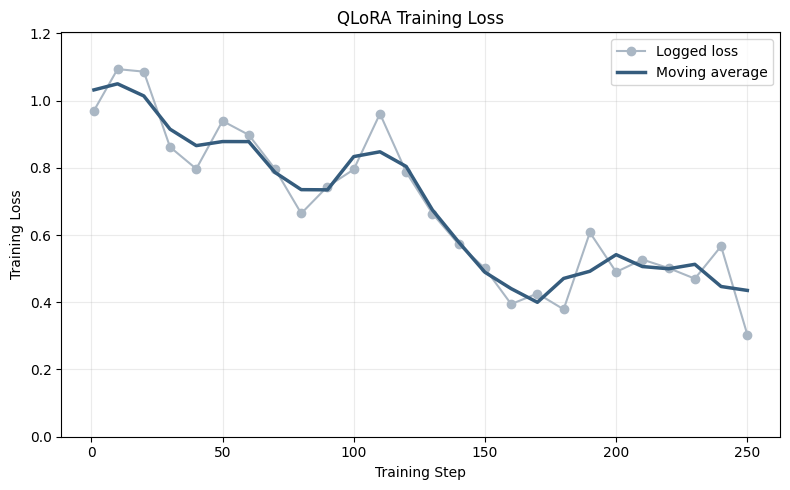

Figure saved: /kaggle/working/figure_2_training_loss.png


In [16]:
FIGURE_2_PATH = WORK_DIR / "figure_2_training_loss.png"

plot_df = training_log_df.sort_values("step").copy()
plot_df["smoothed_loss"] = (
    plot_df["loss"]
    .rolling(window=3, center=True, min_periods=1)
    .mean()
)

plt.figure(figsize=(8, 5))
plt.plot(
    plot_df["step"],
    plot_df["loss"],
    marker="o",
    color="#AAB7C4",
    linewidth=1.5,
    label="Logged loss",
)
plt.plot(
    plot_df["step"],
    plot_df["smoothed_loss"],
    color="#355C7D",
    linewidth=2.5,
    label="Moving average",
)
plt.ylim(0, max(1.2, float(plot_df["loss"].max()) * 1.1))
plt.xlabel("Training Step")
plt.ylabel("Training Loss")
plt.title("QLoRA Training Loss")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_2_PATH, dpi=300, bbox_inches="tight")
plt.show()
print("Figure saved:", FIGURE_2_PATH)


## ۱۰. ارزیابی مدل فاین‌تیون‌شده روی همان ۲۰۰ نمونه


In [17]:
model.gradient_checkpointing_disable()
model.config.use_cache = True
model.eval()

gc.collect()
torch.cuda.empty_cache()

print("Active adapters:", list(model.peft_config.keys()))
print("Model is ready for evaluation.")


Active adapters: ['default']
Model is ready for evaluation.


In [18]:
FINETUNED_PATH = WORK_DIR / "finetuned_v2_results.csv"

if FINETUNED_PATH.exists():
    finetuned_results = pd.read_csv(FINETUNED_PATH).to_dict("records")
else:
    finetuned_results = []

start_index = len(finetuned_results)

for sample_index in tqdm(
    range(start_index, len(test_200)),
    initial=start_index,
    total=len(test_200),
    desc="Fine-tuned evaluation",
):
    sample = test_200[sample_index]
    reference_title = str(sample["text"]).strip()
    prediction = generate_title(sample["image"])
    sample_metrics = calculate_text_metrics(reference_title, prediction)

    finetuned_results.append({
        "sample_index": sample_index,
        "source_index": int(sample["source_index"]),
        "reference": reference_title,
        "prediction": prediction,
        **sample_metrics,
    })

    if (sample_index + 1) % 10 == 0 or sample_index + 1 == len(test_200):
        pd.DataFrame(finetuned_results).to_csv(
            FINETUNED_PATH,
            index=False,
            encoding="utf-8-sig",
        )

finetuned_df = pd.DataFrame(finetuned_results)
assert len(finetuned_df) == 200
finetuned_summary = finetuned_df[METRIC_COLUMNS].mean()

display(finetuned_df.head(5))
display(finetuned_summary.to_frame(name="fine_tuned"))
print("Fine-tuned results saved:", FINETUNED_PATH)


Fine-tuned evaluation:   0%|          | 0/200 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


,sample_index,source_index,reference,prediction,raw_exact_match,normalized_exact_match,levenshtein_similarity,word_f1
0,0,0,تاریخ جنگ های صلیبی (دوره سه جلدی),تاریخ جنگهای صلیبی - جلد اول,0,0,0.617647,0.307692
1,1,1,خلوت مدیر,خلوتمادر: Manager's Privacy,0,0,0.185185,0.000000
2,2,2,فرهنگ جامع فرق اسلامی (دوره سه جلدی),فرهنگ عباسی فارسی - جلد سیزدهم: ث-ی (دوره سوم),0,0,0.413043,0.250000
3,3,3,سمت خدا (دریافت هایی از اساتید اخلاق): به سوی نور,بموم تور: دریافت هایی از اساسات اخلاق,0,0,0.510204,0.235294
4,4,4,شهادت نامه امام حسین (ع) بر پایه منابع معتبر,شهدت نمره ای ما محسین: بر پایه مفسر ال معبر - ...,0,0,0.471698,0.181818


,fine_tuned
raw_exact_match,0.140000
normalized_exact_match,0.140000
levenshtein_similarity,0.601643
word_f1,0.445706


Fine-tuned results saved: /kaggle/working/finetuned_v2_results.csv


## ۱۱. مقایسه نهایی و تحلیل خطا


In [23]:
comparison_df = pd.DataFrame({
    "baseline": baseline_summary,
    "fine_tuned": finetuned_summary,
})
comparison_df["change"] = (
    comparison_df["fine_tuned"] - comparison_df["baseline"]
)

COMPARISON_PATH = WORK_DIR / "metric_comparison_v2.csv"
comparison_df.to_csv(
    COMPARISON_PATH,
    encoding="utf-8-sig",
)

display(comparison_df)
print("Comparison saved:", COMPARISON_PATH)


,baseline,fine_tuned,change
raw_exact_match,0.045000,0.140000,0.095000
normalized_exact_match,0.050000,0.140000,0.090000
levenshtein_similarity,0.479972,0.601643,0.121671
word_f1,0.340218,0.445706,0.105487


Comparison saved: /kaggle/working/metric_comparison_v2.csv


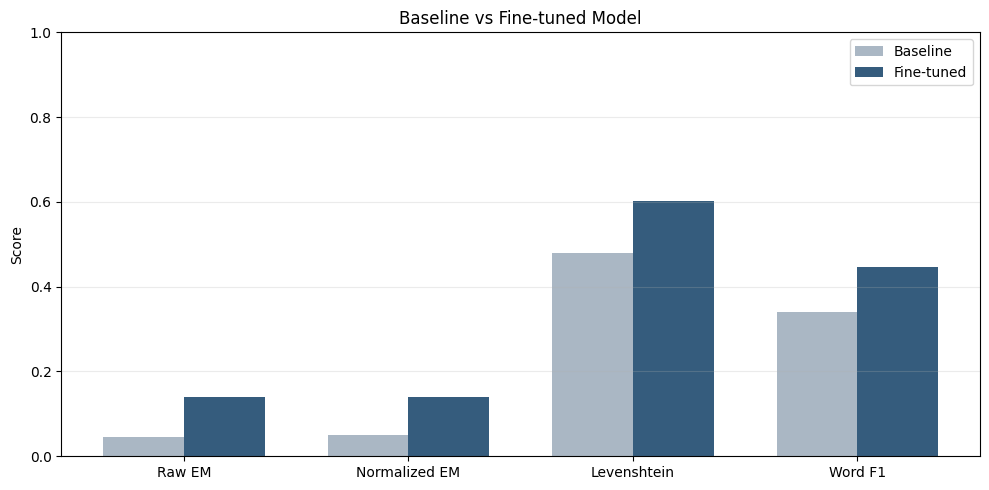

Figure saved: /kaggle/working/figure_3_model_comparison.png


In [20]:
FIGURE_3_PATH = WORK_DIR / "figure_3_model_comparison.png"

x_positions = list(range(len(METRIC_COLUMNS)))
bar_width = 0.36

plt.figure(figsize=(10, 5))
plt.bar(
    [x - bar_width / 2 for x in x_positions],
    comparison_df.loc[METRIC_COLUMNS, "baseline"],
    width=bar_width,
    label="Baseline",
    color="#AAB7C4",
)
plt.bar(
    [x + bar_width / 2 for x in x_positions],
    comparison_df.loc[METRIC_COLUMNS, "fine_tuned"],
    width=bar_width,
    label="Fine-tuned",
    color="#355C7D",
)
plt.xticks(x_positions, [
    "Raw EM",
    "Normalized EM",
    "Levenshtein",
    "Word F1",
])
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Baseline vs Fine-tuned Model")
plt.grid(axis="y", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_3_PATH, dpi=300, bbox_inches="tight")
plt.show()
print("Figure saved:", FIGURE_3_PATH)


In [21]:
analysis_df = baseline_df.merge(
    finetuned_df,
    on=["sample_index", "source_index", "reference"],
    suffixes=("_baseline", "_fine_tuned"),
)
analysis_df["levenshtein_change"] = (
    analysis_df["levenshtein_similarity_fine_tuned"]
    - analysis_df["levenshtein_similarity_baseline"]
)
analysis_df["word_f1_change"] = (
    analysis_df["word_f1_fine_tuned"]
    - analysis_df["word_f1_baseline"]
)

print("Improved:", int((analysis_df["levenshtein_change"] > 0).sum()))
print("Unchanged:", int((analysis_df["levenshtein_change"] == 0).sum()))
print("Worsened:", int((analysis_df["levenshtein_change"] < 0).sum()))

WORST_CASES_PATH = WORK_DIR / "worst_cases_v2.csv"
worst_cases_df = analysis_df.nsmallest(20, "levenshtein_change")
worst_cases_df.to_csv(
    WORST_CASES_PATH,
    index=False,
    encoding="utf-8-sig",
)
display(worst_cases_df[[
    "sample_index",
    "reference",
    "prediction_baseline",
    "prediction_fine_tuned",
    "levenshtein_change",
    "word_f1_change",
]].head(10))


Improved: 131
Unchanged: 28
Worsened: 41


,sample_index,reference,prediction_baseline,prediction_fine_tuned,levenshtein_change,word_f1_change
163,163,ظفرنامه,ظفرنامه,ظفر نامه (نشر مولی),-0.631579,-1.000000
141,141,نهایة الحکمه,نهایتالحكمة,نهایتالحكمه: علامه سید محمدحسین طباطبایی,-0.608333,0.000000
49,49,ملک نبی: شوش,ملک نبی مشوشه,مناطق جنگی ایران 10: ملک نبی فشوشی,-0.475113,-0.133333
56,56,مادران 7: شهید سید داوود سالاری به روایت مادر,مادران: شهید سالاری به روايت مادران,ماهدران - جلد سی و یکم,-0.333333,-0.666667
199,199,الاعلام بمناقب الاسلام,الاعلام بمناقب الإسلام,الاعلام بمناقب الامام علی (ع),-0.299373,-0.166667
166,166,شرح قصیده اسرار الحکمه,سرار الحكمه,سرایر الحکمه (نشر قصیده),-0.291667,-0.083333
103,103,عقل در اخلاق از نظرگاه غزالی و هیوم,عقل دخالون از نظر طارق غزه‌یه‌یم,عقل اخلاقی شیدید,-0.228571,-0.068182
157,157,کتاب الایضاح فی التفسیر,کتاب الاعلامی فی التفسیر,کتاب الابراج فی التفسیر - جلد سوم,-0.227273,-0.204545
12,12,نسیم حدیث,زیبم حیدریث,زیتون حیدریه,-0.212121,0.000000
23,23,پژوهشی درباره حدیث کسا,حدیث کسا,حدیث کسا: پژوهشی درباره,-0.189723,0.083333


## ۱۲. ذخیره خروجی‌های نهایی


In [22]:
SUMMARY_PATH = WORK_DIR / "results_summary_v2.json"

summary_payload = {
    "model_id": MODEL_ID,
    "prompt": PROMPT_V2,
    "train_samples": len(train_1000),
    "test_samples": len(test_200),
    "baseline": {
        key: float(value)
        for key, value in baseline_summary.items()
    },
    "fine_tuned": {
        key: float(value)
        for key, value in finetuned_summary.items()
    },
    "change": {
        key: float(value)
        for key, value in comparison_df["change"].items()
    },
    "training": train_result_v2.metrics,
}

SUMMARY_PATH.write_text(
    json.dumps(summary_payload, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

adapter_zip_path = shutil.make_archive(
    str(WORK_DIR / "final_adapter_v2"),
    "zip",
    root_dir=str(FINAL_ADAPTER_PATH),
)

final_outputs = [
    MANIFEST_PATH,
    BASELINE_PATH,
    FINETUNED_PATH,
    TRAINING_LOG_PATH,
    COMPARISON_PATH,
    WORST_CASES_PATH,
    FIGURE_1_PATH,
    FIGURE_2_PATH,
    FIGURE_3_PATH,
    SUMMARY_PATH,
    Path(adapter_zip_path),
]

print("Final outputs:")
for output_path in final_outputs:
    print(output_path, "OK" if output_path.exists() else "MISSING")


Final outputs:
/kaggle/working/selection_manifest.json OK
/kaggle/working/baseline_v2_results.csv OK
/kaggle/working/finetuned_v2_results.csv OK
/kaggle/working/training_v2_loss_history.csv OK
/kaggle/working/metric_comparison_v2.csv OK
/kaggle/working/worst_cases_v2.csv OK
/kaggle/working/figure_1_baseline_metrics.png OK
/kaggle/working/figure_2_training_loss.png OK
/kaggle/working/figure_3_model_comparison.png OK
/kaggle/working/results_summary_v2.json OK
/kaggle/working/final_adapter_v2.zip OK


## نکته روش‌شناختی

بررسی نمونه‌های خطا نشان داد برخی رفرنس‌های دیتاست شامل عباراتی هستند که روی جلد دیده نمی‌شوند. بنابراین Raw Exact Match باید همراه با Normalized Exact Match، Levenshtein Similarity و Word F1 تفسیر شود. هیچ‌یک از معیارها بعد از مشاهده نتایج تغییر داده نشده‌اند.
